# First simulation

This notebook creates a very simple 2-group scattering problem to show how to construct operators and take derivatives

In [94]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
jax.config.update("jax_enable_x64", True)
import jax_sn

We just create a simple linear domain (1D) and give each element the same simple isotropic cross section:

In [95]:
n_elements   = 10
vertices     = jnp.linspace(0, 1, n_elements + 1)[:, None]
connectivity = jnp.array([(i, i + 1) for i in range(n_elements)])

xs_total     = jnp.array([[1.0, 0.2]])
xs_scatter   = jnp.array([[[
                    [0.9, 0.0], 
                    [0.05, 0.1]
                ]]])

from jax_sn.domain.cross_sections import CrossSectionData, CrossSectionsIndexed
cross_sections = CrossSectionData(
    total      = xs_total,
    scattering = xs_scatter,
)
cross_sections_indexed = CrossSectionsIndexed(jnp.arange(n_elements), cross_sections)
from jax_sn.domain import Domain


domain = Domain.from_mesh_and_cross_sections(mesh = (vertices, connectivity), 
                                             face_template = jnp.array([[0],[1]]), 
                                             cross_sections_indexed = cross_sections_indexed)

The face template determines which face contains which vertices (must be consistent with your Element!)

Now we construct a SolutionDomain from it and print all the SpatialData it contains:

In [113]:
from jax_sn.solution_domain import BasixLagrangianSimplex, SolutionDomain

element_order = 1
element       = BasixLagrangianSimplex(element_order, 1)

solution_domain = SolutionDomain.from_element_and_domain(element = element, domain = domain)


Now we are going to construct the multigroup operator! As mentioned, this requires a particular strategy. 
We will use a simple default (non-optimal!) strategy to explain it:

In [114]:
from jax_sn.operator_creation import DefaultMultiGroupStrategy

print(DefaultMultiGroupStrategy.default_multi_group_strategy())

MultiGroupScanStrategy(
  single_group_chain_strategy=ComposedSingleGroupChainStrategy(
    transport_strategy=VmapAnglesForward(inner=VmapForward()),
    transport_inversion_strategy=VmapAngles(inner=VmapSweep()),
    moment_strategy=EinsumFluxMoment(),
    discrete_strategy=EinsumFluxMoment(),
    mass_strategy=LaxMass(),
    scatter_strategy=IndexedScatter()
  ),
  single_group_gather_scatter_strategy=BroadcastedSingleGroupGather(),
  checkpoint=True
)


What does this mean? 

First, `MultiGroupScanStrategy` just means we scan over each group (or serially compute them), so we only use single group strategies. In the single-group version we have 

$$ \mathbf{I} - \mathbf{M}_g \mathbf{T}^{-1}_g \mathbf{H}_g \mathbf{D}_g\mathbf{S}_{g} $$

(subscript indicates single-group versions). The `single_group_gather_scatter_strategy` means the operation that gathers all scattering contributions in a single group and is $\mathbf{S}_g$. Now, we only need the chain  $\mathbf{M}_g \mathbf{T}^{-1}_g \mathbf{D}_g \mathbf{H}_g $, which is its own strategy (`single_group_chain_strategy`).

The chain strategy is a `ComposedSingleGroupChainStrategy`, which means each operator is defined separately.

The moment and discrete strategies are just einsums (`EinsumFluxMoment`), the mass strategy ($\mathbf{H}$) is a Lax operator, and the scatter strategy a indexed kernel (`IndexedScatter`). 

The transport operator is somewhat special: it is an inversion in its own right and it also maps over all angles! Differentiability requires a forward strategy as well: here, we just vmap over the angles (`VmapAnglesForward`) and vmap over all elements (`VmapForward`), while the inversion strategy also vmaps over the angles (`VmapAngles`) using as single-angle function `VmapSweep`.


We now just create the MultiGroupOperator, but we also need a quadrature set for that:

In [115]:
from jax_sn.operators.multi_group_operator import MultiGroupOperator

from jax_sn.operator_creation import create_multi_group_operator

quadrature_order = 3 
quadrature_set   = jax_sn.quadrature_set.create_tn_quadrature_set(quadrature_order)

mgop = create_multi_group_operator(solution_domain = solution_domain,
                            quadrature_set   = quadrature_set,
                            multi_group_strategy = DefaultMultiGroupStrategy.default_multi_group_strategy())

You can also see the angular data and non-differentiable topological ordering sweep_data.

## Solving

Solving is easy in this formulation!
We just use a simple right-hand-side of all ones and a lineax BiCGSTAB solver:

In [116]:
import lineax as lx

bicgstab = lx.BiCGStab(rtol = 1e-10, atol = 1e-10)

solution = lx.linear_solve(mgop, jnp.ones_like(mgop.out_structure()), solver = bicgstab)

print("Converged in" , solution.stats['num_steps'], "steps")

Converged in 6 steps


We can easily plot it using the built-in interpolation:

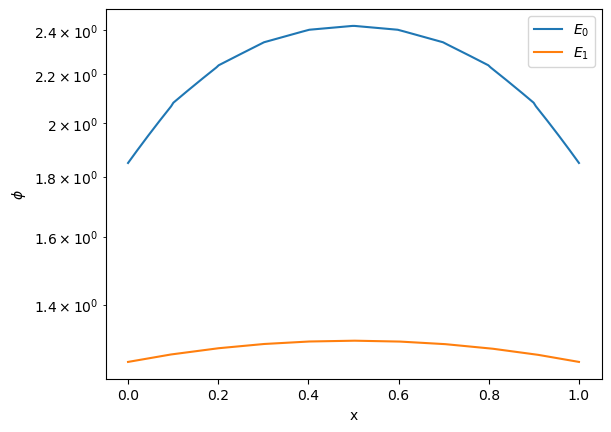

In [117]:
x           = jnp.linspace(0,1,200)[:, None] # make it batch of 200 points in 1D
scalar_flux = solution_domain.interpolate(x, solution.value[:,0]) # interpolate *scalar flux l=0*

plt.semilogy(x[:,0], scalar_flux.T, label= ["$E_0$", "$E_1$"])
plt.legend()
plt.xlabel("x")
_ = plt.ylabel(r"$\phi$")


where you can clearly see the discontinuities and the linear elements

## Obtaining Derivatives

Derivatives requires also parametrising the Jacobian calculation. 
We show how to do it here:

In [118]:
from jax_sn.parametrisation.multigroup_parametrisation import VerticesXSTheta, reconstruct_multigroup_operator_including_toposort
import equinox as eqx

@eqx.filter_jit
def solve_and_sum(vertices, mgop, rhs ):
    mgop_param = reconstruct_multigroup_operator_including_toposort(mgop, 
                                                                    VerticesXSTheta(vertices, 
                                                                                    cross_sections_indexed.cross_section_data), 
                                                                    replace_topological_sort = False) # no toposort change in linear domain!
    solution = lx.linear_solve(mgop_param, rhs, solver = bicgstab)
    return jnp.sum(solution.value)

rhs = jnp.ones_like(mgop.out_structure())
grad_solve_and_sum = eqx.filter_jit(eqx.filter_grad(solve_and_sum))

We can check the results:

In [90]:
print("Result", base_result := solve_and_sum(mgop.data.domain.vertices, mgop, rhs))
print("Gradient", grad_solve_and_sum(mgop.data.domain.vertices, mgop, rhs))
print("Finite difference", (solve_and_sum(mgop.data.domain.vertices.at[0].add(1e-6), mgop, rhs) - base_result)/ 1e-6)

Result 105.67388594889431
Gradient [[-5.28868389e+01]
 [ 6.34249047e+00]
 [ 4.31042290e+00]
 [ 2.69336455e+00]
 [ 1.29832316e+00]
 [-5.15143483e-14]
 [-1.29832316e+00]
 [-2.69336455e+00]
 [-4.31042290e+00]
 [-6.34249047e+00]
 [ 5.28868389e+01]]
Finite difference -52.88686028848133


Let us also check that the adjoint method really just solves back and forth by timing it:

In [91]:
%timeit solve_and_sum(mgop.data.domain.vertices, mgop, rhs).block_until_ready()

6.42 ms ± 57.1 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [92]:
%timeit grad_solve_and_sum(mgop.data.domain.vertices, mgop, rhs).block_until_ready()

13.7 ms ± 123 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
